# Neuro MPRA emVars Across Chromatin Accessibility and ChromHMM

This notebook provides an IGVF Integrative Analysis Working Group (IAWG) example showing how IGVF consortium MPRA, chromatin accessibility/activity, and ChromHMM annotations can be combined for an interactive comparative analysis. It compares emVar and non-emVar groups across selected regulatory annotation panels.

MPRA datasets included:
- Neuro cCRE MPRA
- Tewhey SK-N-SH MPRA
- K562 MPRA
- Won Lab ADD MPRA
- Won Lab CDMPRA
- Won Lab CSMPRA
- Won Lab SCZ MPRA, HEK293
- Won Lab SCZ MPRA, HNP

Won Lab readouts are shown separately by assay. Because the Won Lab datasets are brain/neuro-focused, their annotation panel is restricted to brain, neurosphere, DLPFC, and neuronal/glial nuclei signals.


In [1]:
from pathlib import Path
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency

def find_iawg_root(start=Path.cwd()):
    for path in [start.resolve(), *start.resolve().parents]:
        if (path / 'Data/processed').exists() and (path / 'Data/raw').exists():
            return path
    raise FileNotFoundError('Could not find the IAWG Data directory above the current working directory.')

def first_existing_path(*paths):
    for path in paths:
        if path.exists():
            return path
    return paths[-1]

ROOT = find_iawg_root()
RAW = ROOT / 'Data/raw'
PROCESSED = ROOT / 'Data/processed'
WON = ROOT / 'Data/Won_Lab_Cleaned'
OUTDIR = PROCESSED / 'plots/emvar_chracc_chromhmm_notebook'
PLOTDIR = first_existing_path(Path('../plots/Neuro_MPRA_vs_chracc_chromhmm'), OUTDIR)
OUTDIR.mkdir(parents=True, exist_ok=True)
PLOTDIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
OUTDIR.relative_to(ROOT)


PosixPath('Data/processed/plots/emvar_chracc_chromhmm_notebook')

## Selected Annotation Panel

Only a small set of biologically relevant assays is shown to keep the notebook readable. Won Lab datasets use a brain/neuro-only annotation panel; broader comparison datasets retain a compact cross-context panel.

In [2]:
DEFAULT_SIGNAL_COLS = [
    'average_ATAC.seq_imputed_Brain',
    'average_DNase.seq_imputed_Brain',
    'average_H3K27ac_imputed_Brain',
    'average_ATAC.seq_imputed_Neurosph',
    'DLPFC_glia',
    'DLPFC_neuron',
    'human_LHX2nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc',
    'human_NEUNnuclei_H3K27ac_epilepsy_pooled_hg19.ucsc',
    'average_ATAC.seq_imputed_BloodandT.cell',
    'average_ATAC.seq_imputed_Lymphoblastoid',
    'average_ATAC.seq_imputed_Cancer',
]

WON_BRAIN_SIGNAL_COLS = [
    'average_ATAC.seq_imputed_Brain',
    'average_DNase.seq_imputed_Brain',
    'average_H3K27ac_imputed_Brain',
    'average_ATAC.seq_imputed_Neurosph',
    'average_ATAC.seq_imputed_PNS',
    'DLPFC_glia',
    'DLPFC_neuron',
    'human_LHX2nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc',
    'human_NEUNnuclei_H3K27ac_epilepsy_pooled_hg19.ucsc',
    'human_OLIG2nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc',
    'human_PU1nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc',
    'human_LHX2nuclei_atac_epilepsy_pooled_hg19.ucsc',
    'human_NEUNnuclei_atac_epilepsy_pooled_hg19.ucsc',
    'human_OLIG2nuclei_atac_epilepsy_pooled_hg19.ucsc',
    'human_PU1nuclei_atac_epilepsy_pooled_hg19.ucsc',
]

DEFAULT_CHROMHMM_IDS = ['E007', 'E010', 'E053', 'E073', 'E116', 'E123']
WON_BRAIN_CHROMHMM_IDS = ['E007', 'E010', 'E053', 'E073']

CHROMHMM_LABELS = {
    'E007': 'H1-derived NPC',
    'E010': 'H9-derived neuron',
    'E053': 'Cortex-derived neurospheres',
    'E073': 'DLPFC',
    'E116': 'GM12878 lymphoblastoid',
    'E123': 'K562 leukemia',
}

WON_EMVAR_FILE = WON / 'Integrated_emVar_results_Won_v2.tsv'
WON_CHRACC_FILE = PROCESSED / 'Wonlab_chromatine_accessibility.csv'
WON_DATASETS = [
    ('Won_ADD_MPRA', 'Won Lab ADD MPRA', 'emVar_addmpra'),
    ('Won_CDMPRA', 'Won Lab CDMPRA', 'emVar_cdmpra'),
    ('Won_CSMPRA', 'Won Lab CSMPRA', 'emVar_csmpra'),
    ('Won_SCZ_HEK293', 'Won Lab SCZ MPRA HEK293', 'allelic_sczmpra_hek293'),
    ('Won_SCZ_HNP', 'Won Lab SCZ MPRA HNP', 'allelic_sczmpra_hnp'),
]

DATASETS = [
    {
        'name': 'Neuro_cCRE',
        'label': 'Neuro cCRE MPRA',
        'emvar_file': RAW / 'shendure_ahituv_kircher_cCRE_variants_neuro_MPRA_emVar_calling.tsv.gz',
        'chracc_file': PROCESSED / 'Neuro_chromatine_accessibility.csv',
        'emvar_cols': None,
        'use_chracc_background': True,
        'signal_cols': DEFAULT_SIGNAL_COLS,
        'chromhmm_ids': DEFAULT_CHROMHMM_IDS,
    },
    {
        'name': 'Tewhey_SKNSH',
        'label': 'Tewhey SK-N-SH MPRA',
        'emvar_file': RAW / 'Tewhey_MPRA_SKNSH_emVar_calling.tsv.gz',
        'chracc_file': PROCESSED / 'Blood_Tewhey_chromatine_accessibility.csv',
        'emvar_cols': None,
        'use_chracc_background': False,
        'signal_cols': DEFAULT_SIGNAL_COLS,
        'chromhmm_ids': DEFAULT_CHROMHMM_IDS,
    },
    {
        'name': 'K562',
        'label': 'K562 MPRA',
        'emvar_file': RAW / 'k562_combined_final_processed.tsv',
        'chracc_file': PROCESSED / 'K562_chromatine_accessibility.csv',
        'emvar_cols': ['emVar'],
        'use_chracc_background': False,
        'signal_cols': DEFAULT_SIGNAL_COLS,
        'chromhmm_ids': DEFAULT_CHROMHMM_IDS,
    },
]

for name, label, emvar_col in WON_DATASETS:
    DATASETS.append({
        'name': name,
        'label': label,
        'emvar_file': WON_EMVAR_FILE,
        'chracc_file': WON_CHRACC_FILE,
        'emvar_cols': [emvar_col],
        'require_emvar_observed': True,
        'use_chracc_background': False,
        'signal_cols': WON_BRAIN_SIGNAL_COLS,
        'chromhmm_ids': WON_BRAIN_CHROMHMM_IDS,
    })

def normalize_spdi(x):
    x = str(x)
    m = re.match(r'^NC_0*([0-9]+)\.[0-9]+:(.*)$', x)
    if not m:
        return x
    chrom = {'23': 'X', '24': 'Y'}.get(m.group(1), m.group(1))
    return f'chr{chrom}:{m.group(2)}'

def truthy(series):
    return series.astype(str).str.lower().isin(['true', 't', '1', 'yes', 'emvar'])

def observed(series):
    text = series.astype(str).str.strip().str.lower()
    return series.notna() & ~text.isin(['', 'nan', 'none', 'na'])

def read_table(path, **kwargs):
    if str(path).endswith('.csv'):
        return pd.read_csv(path, low_memory=False, **kwargs)
    return pd.read_csv(path, sep='\t', low_memory=False, **kwargs)

def header(path):
    return list(read_table(path, nrows=0).columns)

def read_emvar(path, emvar_cols=None, require_observed=False):
    dat = read_table(path)
    if 'SPDI' not in dat.columns:
        raise ValueError(f'Missing SPDI in {path}')
    if emvar_cols is None:
        emvar_cols = [c for c in dat.columns if c != 'SPDI'][:1]
    missing = [c for c in emvar_cols if c not in dat.columns]
    if missing:
        raise ValueError(f'Missing emVar columns in {path}: {missing}')
    out = dat[['SPDI'] + emvar_cols].copy()
    if require_observed:
        keep = pd.concat([observed(out[c]) for c in emvar_cols], axis=1).any(axis=1)
        out = out[keep].copy()
    out['SPDI_norm'] = out['SPDI'].map(normalize_spdi)
    call_mat = pd.concat([truthy(out[c]) for c in emvar_cols], axis=1)
    out['emVar_bool'] = call_mat.any(axis=1)
    out['emVar'] = np.where(out['emVar_bool'], 'emVar', 'non-emVar')
    return out.drop_duplicates('SPDI_norm')

def selected_chromhmm_cols(chromhmm_ids):
    return [f'{x}_15_coreMarks_dense' for x in chromhmm_ids]

def read_chracc_selected(path, signal_cols, chromhmm_cols):
    cols = header(path)
    keep = ['SPDI'] + [c for c in signal_cols + chromhmm_cols if c in cols]
    dat = read_table(path, usecols=keep)
    dat['SPDI_norm'] = dat['SPDI'].map(normalize_spdi)
    return dat.drop_duplicates('SPDI_norm')

def clean_feature_name(name):
    repl = {
        'average_ATAC.seq_imputed_Brain': 'Brain ATAC-seq',
        'average_DNase.seq_imputed_Brain': 'Brain DNase-seq',
        'average_H3K27ac_imputed_Brain': 'Brain H3K27ac',
        'average_ATAC.seq_imputed_Neurosph': 'Neurosphere ATAC-seq',
        'average_ATAC.seq_imputed_PNS': 'PNS ATAC-seq',
        'DLPFC_glia': 'DLPFC glia',
        'DLPFC_neuron': 'DLPFC neuron',
        'human_LHX2nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc': 'LHX2 nuclei H3K27ac',
        'human_NEUNnuclei_H3K27ac_epilepsy_pooled_hg19.ucsc': 'NEUN nuclei H3K27ac',
        'human_OLIG2nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc': 'OLIG2 nuclei H3K27ac',
        'human_PU1nuclei_H3K27ac_epilepsy_pooled_hg19.ucsc': 'PU1 nuclei H3K27ac',
        'human_LHX2nuclei_atac_epilepsy_pooled_hg19.ucsc': 'LHX2 nuclei ATAC',
        'human_NEUNnuclei_atac_epilepsy_pooled_hg19.ucsc': 'NEUN nuclei ATAC',
        'human_OLIG2nuclei_atac_epilepsy_pooled_hg19.ucsc': 'OLIG2 nuclei ATAC',
        'human_PU1nuclei_atac_epilepsy_pooled_hg19.ucsc': 'PU1 nuclei ATAC',
        'average_ATAC.seq_imputed_BloodandT.cell': 'Blood/T-cell ATAC-seq',
        'average_ATAC.seq_imputed_Lymphoblastoid': 'Lymphoblastoid ATAC-seq',
        'average_ATAC.seq_imputed_Cancer': 'Cancer ATAC-seq',
    }
    return repl.get(name, name)

def chromhmm_group(state):
    state = re.sub(r'^[0-9]+_', '', str(state))
    if state in ['TssA', 'TssAFlnk', 'TssBiv']:
        return 'Promoter/TSS'
    if state in ['Enh', 'EnhG', 'EnhBiv']:
        return 'Enhancer'
    if state in ['Tx', 'TxWk', 'TxFlnk']:
        return 'Transcribed'
    if state in ['ReprPC', 'ReprPCWk', 'Het', 'Quies']:
        return 'Repressed/Quiescent'
    if state == 'BivFlnk':
        return 'Bivalent'
    if state in ['', 'nan', 'None']:
        return np.nan
    return 'Other'


## Load and Join Datasets

In [3]:
def load_joined_dataset(ds):
    emvar = read_emvar(ds['emvar_file'], ds.get('emvar_cols'), ds.get('require_emvar_observed', False))
    chromhmm_cols_requested = selected_chromhmm_cols(ds.get('chromhmm_ids', DEFAULT_CHROMHMM_IDS))
    chracc = read_chracc_selected(ds['chracc_file'], ds.get('signal_cols', DEFAULT_SIGNAL_COLS), chromhmm_cols_requested)
    if ds.get('use_chracc_background'):
        dat = chracc.merge(emvar[['SPDI_norm', 'emVar_bool']], on='SPDI_norm', how='left')
        dat['emVar_bool'] = dat['emVar_bool'].fillna(False)
        dat['emVar'] = np.where(dat['emVar_bool'], 'emVar', 'non-emVar')
    else:
        dat = emvar[['SPDI_norm', 'emVar_bool', 'emVar']].merge(chracc, on='SPDI_norm', how='inner')
    signal_cols = [c for c in ds.get('signal_cols', DEFAULT_SIGNAL_COLS) if c in dat.columns]
    chromhmm_cols = [c for c in chromhmm_cols_requested if c in dat.columns]
    summary = {
        'dataset': ds['name'],
        'label': ds['label'],
        'emvar_columns': ', '.join(ds.get('emvar_cols') or []),
        'emvar_input_n': len(emvar),
        'chracc_input_n': len(chracc),
        'joined_n': len(dat),
        'emvar_joined_n': int((dat['emVar'] == 'emVar').sum()),
        'non_emvar_joined_n': int((dat['emVar'] == 'non-emVar').sum()),
        'chracc_background_used': bool(ds.get('use_chracc_background')),
        'signal_columns': ', '.join(clean_feature_name(c) for c in signal_cols),
        'chromhmm_samples': ', '.join(CHROMHMM_LABELS.get(c.replace('_15_coreMarks_dense', ''), c) for c in chromhmm_cols),
    }
    return dat, signal_cols, chromhmm_cols, summary

loaded = {}
summaries = []
for ds in DATASETS:
    print(f"Loading {ds['label']}")
    dat, signal_cols, chromhmm_cols, summary = load_joined_dataset(ds)
    loaded[ds['name']] = {'config': ds, 'data': dat, 'signal_cols': signal_cols, 'chromhmm_cols': chromhmm_cols}
    summaries.append(summary)

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(OUTDIR / 'selected_emvar_chracc_chromhmm_summary.tsv', sep='\t', index=False)
summary_df

Loading Neuro cCRE MPRA


/nas/longleaf/home/mhg/tmp/ipykernel_2583401/508074425.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dat['emVar_bool'] = dat['emVar_bool'].fillna(False)


Loading Tewhey SK-N-SH MPRA
Loading K562 MPRA
Loading Won Lab ADD MPRA
Loading Won Lab CDMPRA
Loading Won Lab CSMPRA
Loading Won Lab SCZ MPRA HEK293
Loading Won Lab SCZ MPRA HNP


,dataset,label,emvar_columns,emvar_input_n,chracc_input_n,joined_n,emvar_joined_n,non_emvar_joined_n,chracc_background_used,signal_columns,chromhmm_samples
0,Neuro_cCRE,Neuro cCRE MPRA,,295,401150,401150,288,400862,True,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."
1,Tewhey_SKNSH,Tewhey SK-N-SH MPRA,,279816,331518,279794,16315,263479,False,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."
2,K562,K562 MPRA,emVar,279913,279891,279891,18271,261620,False,"Blood/T-cell ATAC-seq, Lymphoblastoid ATAC-seq...","GM12878 lymphoblastoid, K562 leukemia"
3,Won_ADD_MPRA,Won Lab ADD MPRA,emVar_addmpra,3490,28865,3485,123,3362,False,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."
4,Won_CDMPRA,Won Lab CDMPRA,emVar_cdmpra,13259,28865,13258,655,12603,False,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."
5,Won_CSMPRA,Won Lab CSMPRA,emVar_csmpra,8784,28865,8764,75,8689,False,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."
6,Won_SCZ_HEK293,Won Lab SCZ MPRA HEK293,allelic_sczmpra_hek293,5069,28865,5064,635,4429,False,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."
7,Won_SCZ_HNP,Won Lab SCZ MPRA HNP,allelic_sczmpra_hnp,5105,28865,5100,250,4850,False,"Brain ATAC-seq, Brain DNase-seq, Brain H3K27ac...","H1-derived NPC, H9-derived neuron, Cortex-deri..."


## emVar Counts

,dataset,emVar,non_emVar,total,emVar_fraction
0,Neuro cCRE MPRA,288,400862,401150,0.000718
1,Tewhey SK-N-SH MPRA,16315,263479,279794,0.058311
2,K562 MPRA,18271,261620,279891,0.065279
3,Won Lab ADD MPRA,123,3362,3485,0.035294
4,Won Lab CDMPRA,655,12603,13258,0.049404
5,Won Lab CSMPRA,75,8689,8764,0.008558
6,Won Lab SCZ MPRA HEK293,635,4429,5064,0.125395
7,Won Lab SCZ MPRA HNP,250,4850,5100,0.049020


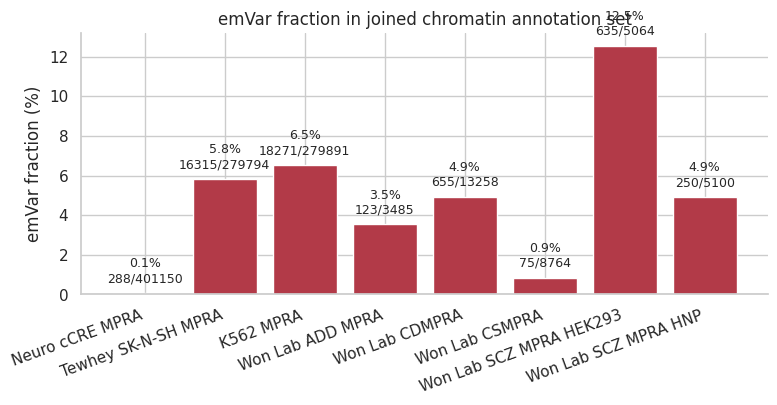

In [4]:
count_rows = []
for name, obj in loaded.items():
    counts = obj['data']['emVar'].value_counts().to_dict()
    count_rows.append({
        'dataset': obj['config']['label'],
        'emVar': counts.get('emVar', 0),
        'non_emVar': counts.get('non-emVar', 0),
        'total': len(obj['data']),
        'emVar_fraction': counts.get('emVar', 0) / len(obj['data']) if len(obj['data']) else np.nan,
    })
count_df = pd.DataFrame(count_rows)
display(count_df)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(count_df['dataset'], count_df['emVar_fraction'] * 100, color='#B23A48')
for i, row in count_df.iterrows():
    ax.text(i, row['emVar_fraction'] * 100 + 0.4, f"{row['emVar_fraction']*100:.1f}%\n{int(row['emVar'])}/{int(row['total'])}", ha='center', va='bottom', fontsize=9)
ax.set_ylabel('emVar fraction (%)')
ax.set_title('emVar fraction in joined chromatin annotation set')
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## Selected chr_acc Signal vs emVar

In [5]:
def chracc_tests(dat, signal_cols, dataset_name):
    rows = []
    for col in signal_cols:
        vals = dat[['emVar', col]].dropna().copy()
        vals[col] = pd.to_numeric(vals[col], errors='coerce')
        vals = vals[np.isfinite(vals[col]) & (vals[col] > 0)]
        a = vals.loc[vals['emVar'] == 'emVar', col]
        b = vals.loc[vals['emVar'] == 'non-emVar', col]
        p = np.nan
        if len(a) > 0 and len(b) > 0:
            p = mannwhitneyu(a, b, alternative='two-sided').pvalue
        rows.append({
            'dataset': dataset_name,
            'feature': col,
            'feature_label': clean_feature_name(col),
            'emvar_n': len(a),
            'non_emvar_n': len(b),
            'emvar_median': a.median() if len(a) else np.nan,
            'non_emvar_median': b.median() if len(b) else np.nan,
            'median_difference': (a.median() - b.median()) if len(a) and len(b) else np.nan,
            'p_value': p,
        })
    out = pd.DataFrame(rows).sort_values('p_value')
    return out

all_tests = []
for name, obj in loaded.items():
    tests = chracc_tests(obj['data'], obj['signal_cols'], name)
    tests.to_csv(OUTDIR / f'{name}_selected_chracc_wilcoxon.tsv', sep='\t', index=False)
    all_tests.append(tests)
all_tests = pd.concat(all_tests, ignore_index=True)
all_tests.to_csv(OUTDIR / 'all_selected_chracc_wilcoxon.tsv', sep='\t', index=False)
all_tests.head(20)

,dataset,feature,feature_label,emvar_n,non_emvar_n,emvar_median,non_emvar_median,median_difference,p_value
0,Neuro_cCRE,average_H3K27ac_imputed_Brain,Brain H3K27ac,288,400514,420.080190,241.076108,179.004083,1.465698e-46
1,Neuro_cCRE,average_DNase.seq_imputed_Brain,Brain DNase-seq,288,400459,608.606795,355.457600,253.149195,3.633235e-37
2,Neuro_cCRE,human_NEUNnuclei_H3K27ac_epilepsy_pooled_hg19....,NEUN nuclei H3K27ac,288,395947,244.904998,107.669999,137.234999,2.374887e-24
3,Neuro_cCRE,average_ATAC.seq_imputed_Neurosph,Neurosphere ATAC-seq,288,400459,461.328752,333.892499,127.436253,7.257827e-24
4,Neuro_cCRE,average_ATAC.seq_imputed_Brain,Brain ATAC-seq,288,400460,459.939753,346.862114,113.077638,1.779428e-23
5,Neuro_cCRE,average_ATAC.seq_imputed_BloodandT.cell,Blood/T-cell ATAC-seq,288,400460,436.312959,346.676057,89.636902,7.259041e-23
6,Neuro_cCRE,average_ATAC.seq_imputed_Cancer,Cancer ATAC-seq,288,400460,437.432688,319.291802,118.140887,3.732307e-22
7,Neuro_cCRE,average_ATAC.seq_imputed_Lymphoblastoid,Lymphoblastoid ATAC-seq,288,400460,517.793798,392.442925,125.350873,6.668616e-20
8,Neuro_cCRE,human_LHX2nuclei_H3K27ac_epilepsy_pooled_hg19....,LHX2 nuclei H3K27ac,288,397437,163.679999,105.279999,58.400000,1.581097e-13
9,Neuro_cCRE,DLPFC_neuron,DLPFC neuron,288,399866,1306.500000,1155.000000,151.500000,8.221556e-05


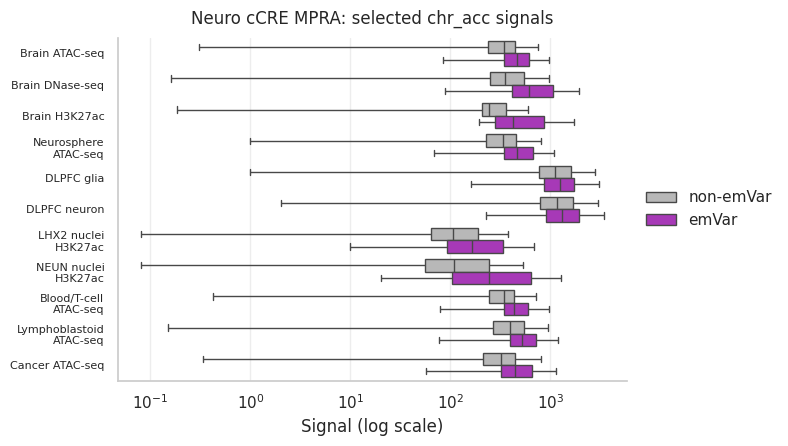

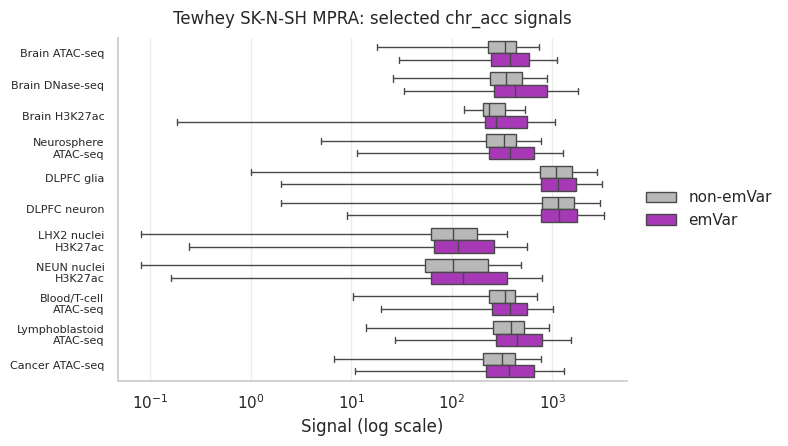

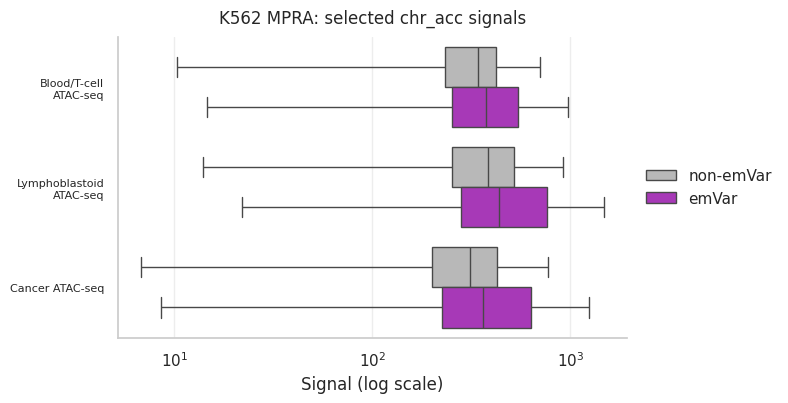

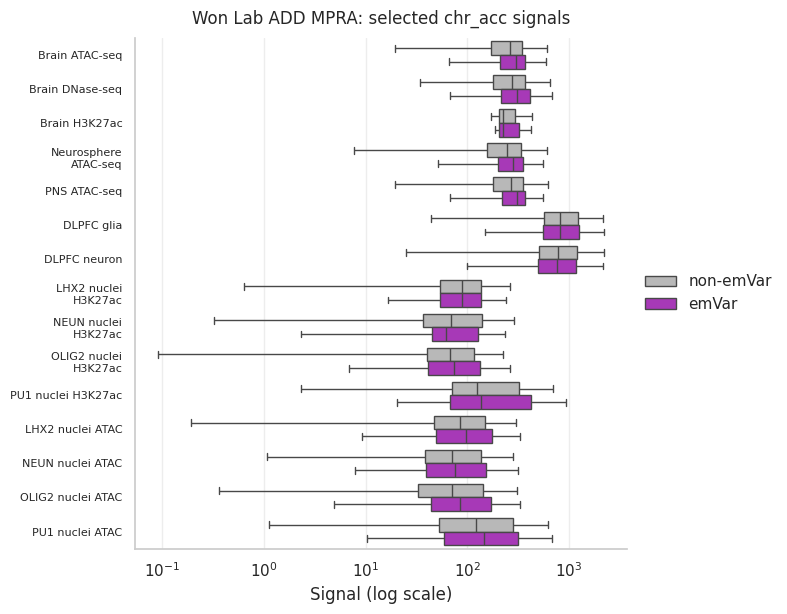

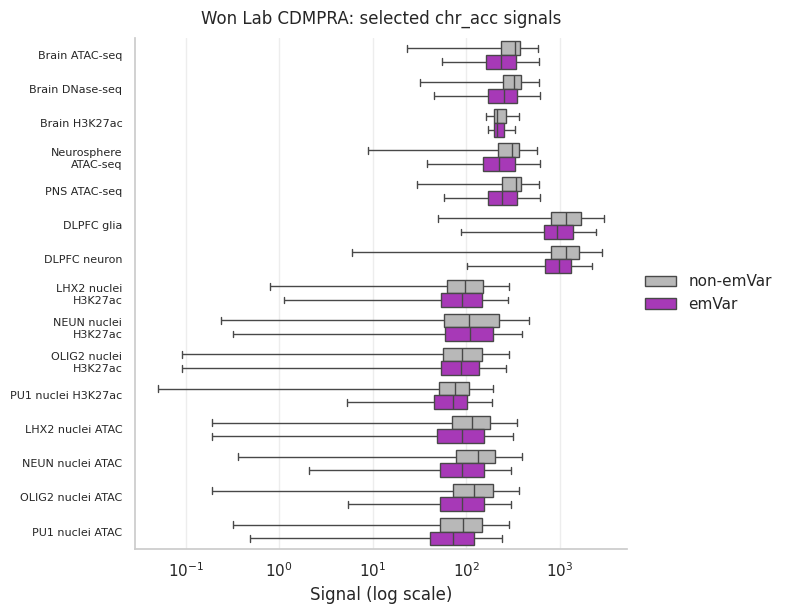

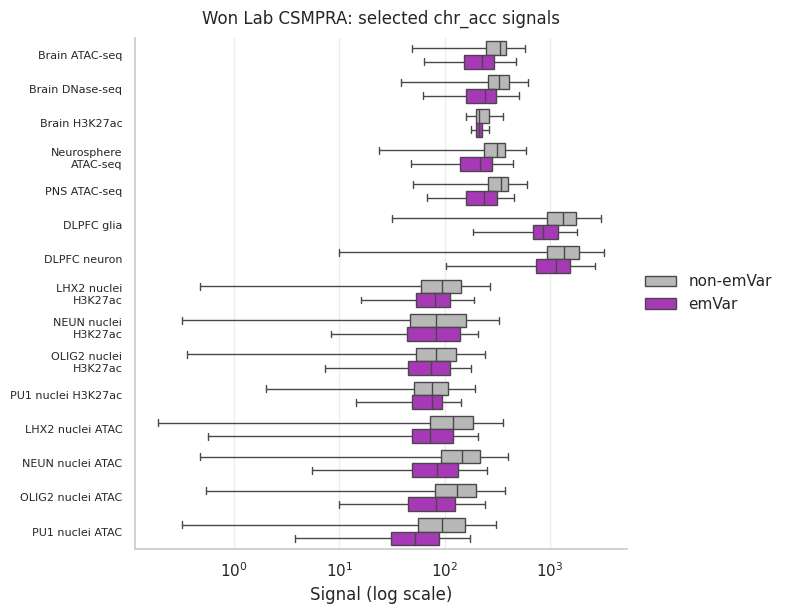

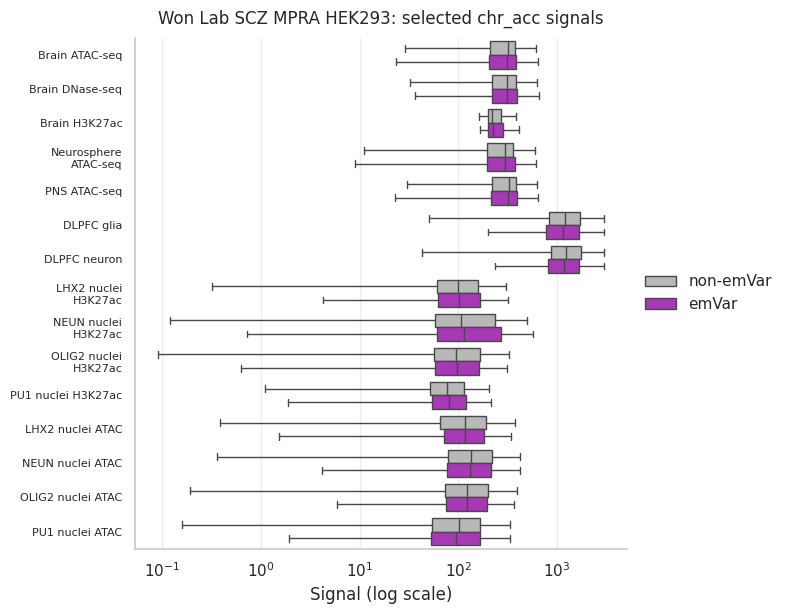

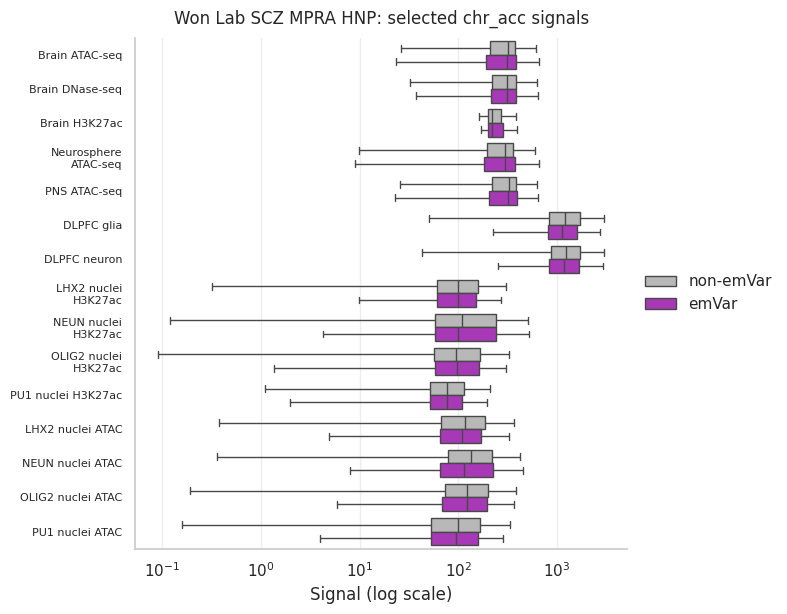

In [6]:
def wrap_label(label, width=20):
    parts = str(label).split()
    lines = []
    current = ''
    for part in parts:
        candidate = part if not current else f'{current} {part}'
        if len(candidate) <= width:
            current = candidate
        else:
            if current:
                lines.append(current)
            current = part
    if current:
        lines.append(current)
    return '\n'.join(lines)

def plot_chracc_dataset(name):
    obj = loaded[name]
    dat = obj['data']
    cols = obj['signal_cols']
    long = dat[['emVar'] + cols].melt(id_vars='emVar', var_name='feature', value_name='value')
    long['value'] = pd.to_numeric(long['value'], errors='coerce')
    long = long[np.isfinite(long['value']) & (long['value'] > 0)].copy()
    long['feature_label'] = long['feature'].map(clean_feature_name)
    order = [clean_feature_name(c) for c in cols]
    wrapped_order = [wrap_label(x, width=18) for x in order]
    label_map = dict(zip(order, wrapped_order))
    long['feature_label_wrapped'] = long['feature_label'].map(label_map)
    long['feature_label_wrapped'] = pd.Categorical(long['feature_label_wrapped'], categories=wrapped_order, ordered=True)
    fig_height = max(4.2, len(cols) * 0.42)
    fig, ax = plt.subplots(figsize=(9.6, fig_height))
    sns.boxplot(
        data=long,
        y='feature_label_wrapped',
        x='value',
        hue='emVar',
        hue_order=['non-emVar', 'emVar'],
        palette={'non-emVar': '#B8B8B8', 'emVar': '#B724CC'},
        showfliers=False,
        ax=ax,
    )
    ax.set_xscale('log')
    ax.set_ylabel('')
    ax.set_xlabel('Signal (log scale)')
    ax.set_title(f"{obj['config']['label']}: selected chr_acc signals", pad=10)
    ax.legend(title='', loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='x', alpha=0.35)
    ax.grid(axis='y', visible=False)
    fig.tight_layout(rect=[0, 0, 0.84, 1])
    fig.savefig(PLOTDIR / f'{name}_selected_chracc_boxplots.png', dpi=300, bbox_inches='tight')
    return fig

for name in loaded:
    fig = plot_chracc_dataset(name)
    plt.show()

## Selected ChromHMM State Composition

In [7]:
def chromhmm_state_table(dat, chromhmm_cols, dataset_name, dataset_label):
    rows = []
    for col in chromhmm_cols:
        sample_id = col.replace('_15_coreMarks_dense', '')
        sample_label = CHROMHMM_LABELS.get(sample_id, sample_id)
        tmp = dat[['emVar', col]].dropna().copy()
        tmp['state_group'] = tmp[col].map(chromhmm_group)
        tmp = tmp.dropna(subset=['state_group'])
        counts = tmp.groupby(['emVar', 'state_group']).size().reset_index(name='n')
        counts['sample_id'] = sample_id
        counts['sample'] = sample_label
        counts['dataset'] = dataset_name
        counts['dataset_label'] = dataset_label
        rows.append(counts)
    if not rows:
        return pd.DataFrame()
    out = pd.concat(rows, ignore_index=True)
    out['prop'] = out['n'] / out.groupby(['dataset', 'sample_id', 'emVar'])['n'].transform('sum')
    return out

state_tables = []
for name, obj in loaded.items():
    states = chromhmm_state_table(obj['data'], obj['chromhmm_cols'], name, obj['config']['label'])
    states.to_csv(OUTDIR / f'{name}_selected_chromhmm_state_proportions.tsv', sep='\t', index=False)
    state_tables.append(states)
all_states = pd.concat(state_tables, ignore_index=True)
all_states.to_csv(OUTDIR / 'all_selected_chromhmm_state_proportions.tsv', sep='\t', index=False)
all_states.head()

,emVar,state_group,n,sample_id,sample,dataset,dataset_label,prop
0,emVar,Enhancer,41,E007,H1-derived NPC,Neuro_cCRE,Neuro cCRE MPRA,0.142361
1,emVar,Other,2,E007,H1-derived NPC,Neuro_cCRE,Neuro cCRE MPRA,0.006944
2,emVar,Promoter/TSS,3,E007,H1-derived NPC,Neuro_cCRE,Neuro cCRE MPRA,0.010417
3,emVar,Repressed/Quiescent,140,E007,H1-derived NPC,Neuro_cCRE,Neuro cCRE MPRA,0.486111
4,emVar,Transcribed,102,E007,H1-derived NPC,Neuro_cCRE,Neuro cCRE MPRA,0.354167


In [8]:
def chromhmm_tests(state_df):
    rows = []
    for (dataset, dataset_label, sample_id, sample), sub in state_df.groupby(['dataset', 'dataset_label', 'sample_id', 'sample']):
        tab = sub.pivot_table(index='emVar', columns='state_group', values='n', aggfunc='sum', fill_value=0)
        p = np.nan
        stat = np.nan
        dof = np.nan
        if tab.shape[0] == 2 and tab.shape[1] > 1 and (tab.sum(axis=1) > 0).all() and (tab.sum(axis=0) > 0).all():
            stat, p, dof, _ = chi2_contingency(tab)
        rows.append({'dataset': dataset, 'dataset_label': dataset_label, 'sample_id': sample_id, 'sample': sample, 'chi2': stat, 'df': dof, 'p_value': p})
    return pd.DataFrame(rows).sort_values('p_value')

chrom_tests = chromhmm_tests(all_states)
chrom_tests.to_csv(OUTDIR / 'all_selected_chromhmm_chisq.tsv', sep='\t', index=False)
chrom_tests.head(20)

,dataset,dataset_label,sample_id,sample,chi2,df,p_value
1,K562,K562 MPRA,E123,K562 leukemia,2437.139682,5,0.000000e+00
7,Tewhey_SKNSH,Tewhey SK-N-SH MPRA,E010,H9-derived neuron,1586.264027,5,0.000000e+00
6,Tewhey_SKNSH,Tewhey SK-N-SH MPRA,E007,H1-derived NPC,1858.437245,5,0.000000e+00
8,Tewhey_SKNSH,Tewhey SK-N-SH MPRA,E053,Cortex-derived neurospheres,1821.496132,5,0.000000e+00
9,Tewhey_SKNSH,Tewhey SK-N-SH MPRA,E073,DLPFC,1816.889496,5,0.000000e+00
0,K562,K562 MPRA,E116,GM12878 lymphoblastoid,1206.634489,5,1.073771e-258
5,Neuro_cCRE,Neuro cCRE MPRA,E073,DLPFC,129.864035,5,2.543482e-26
4,Neuro_cCRE,Neuro cCRE MPRA,E053,Cortex-derived neurospheres,101.581324,5,2.452998e-20
3,Neuro_cCRE,Neuro cCRE MPRA,E010,H9-derived neuron,100.588418,5,3.972194e-20
2,Neuro_cCRE,Neuro cCRE MPRA,E007,H1-derived NPC,80.944512,5,5.323740e-16


/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

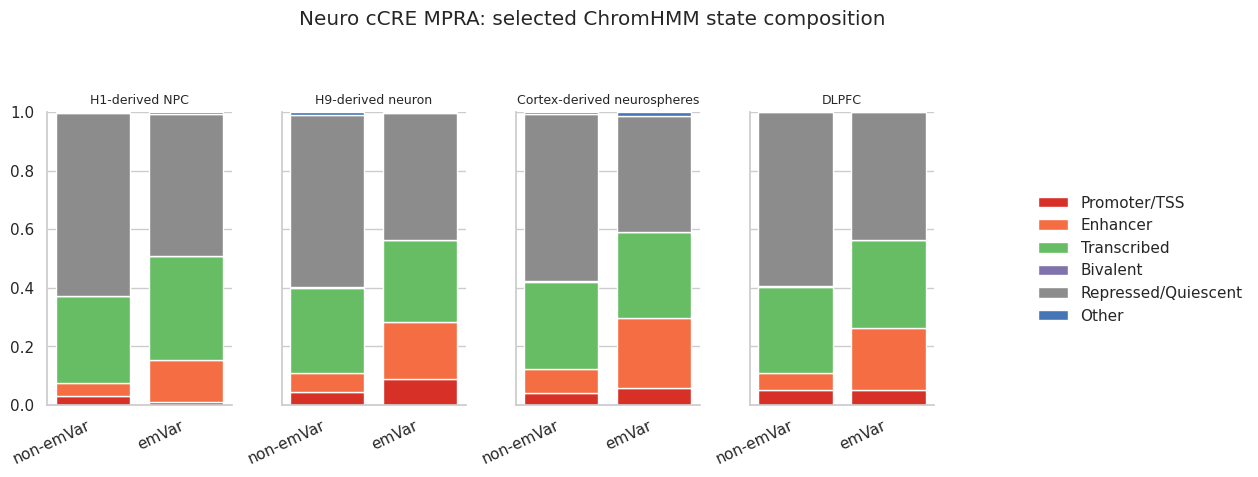

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

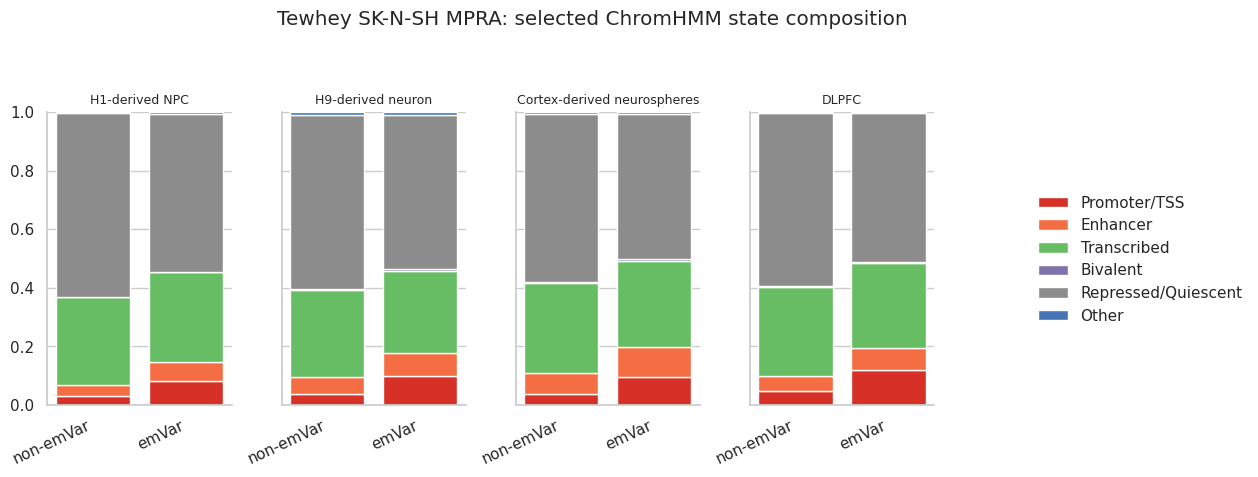

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')


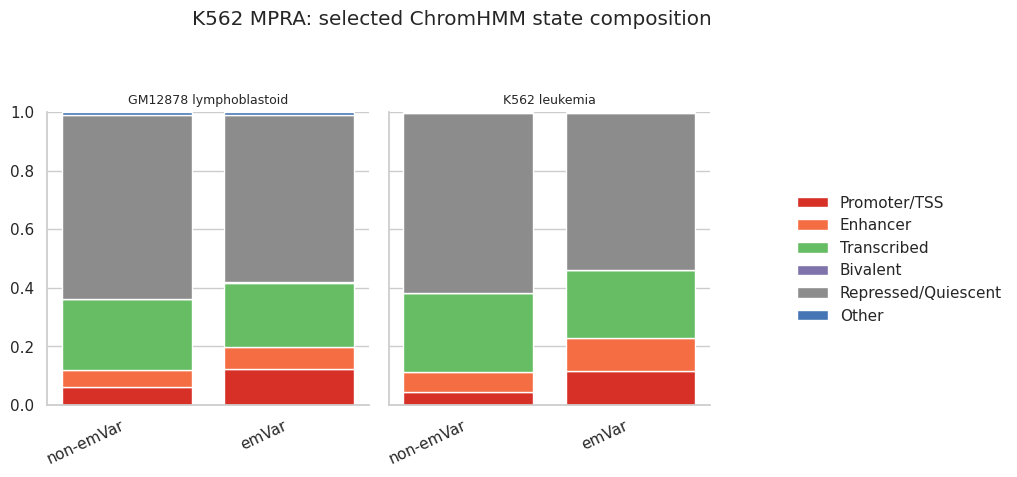

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

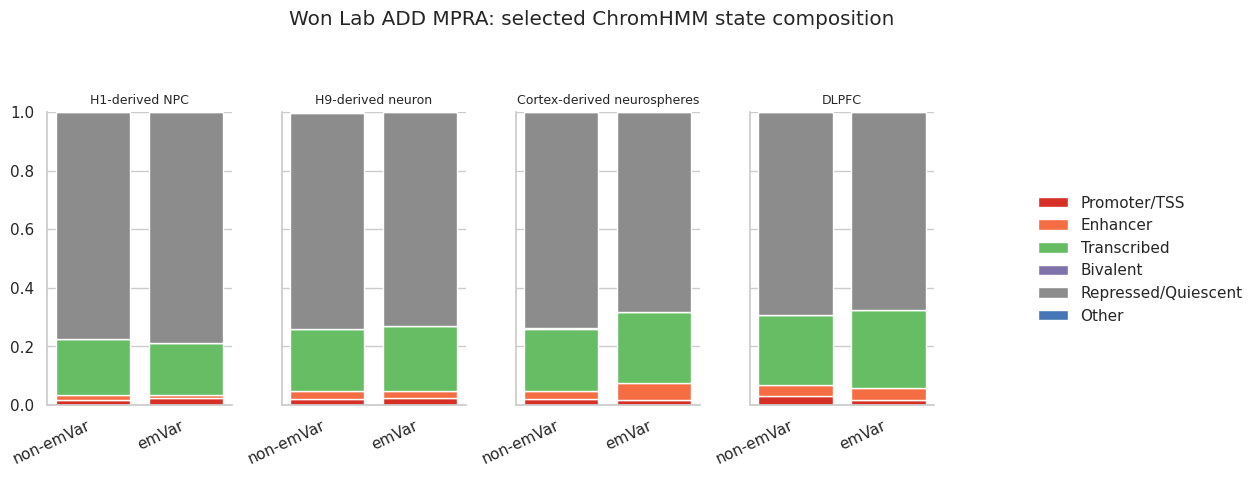

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

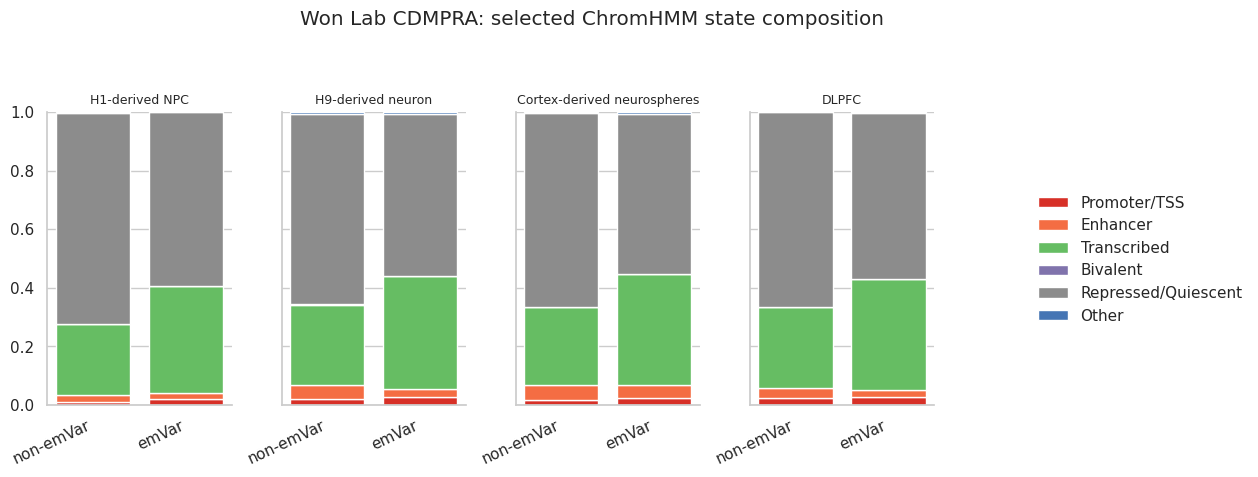

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

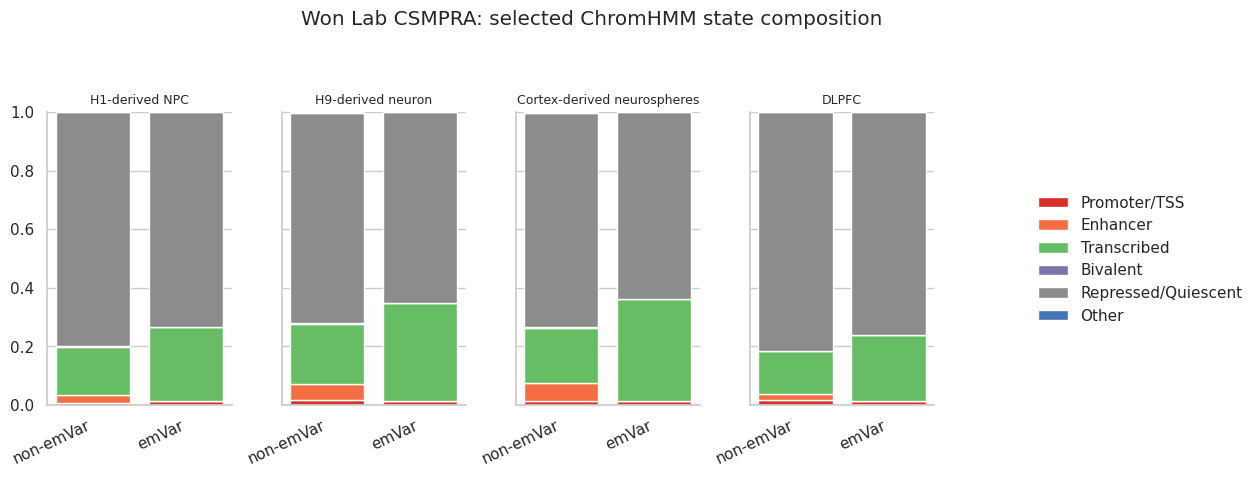

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

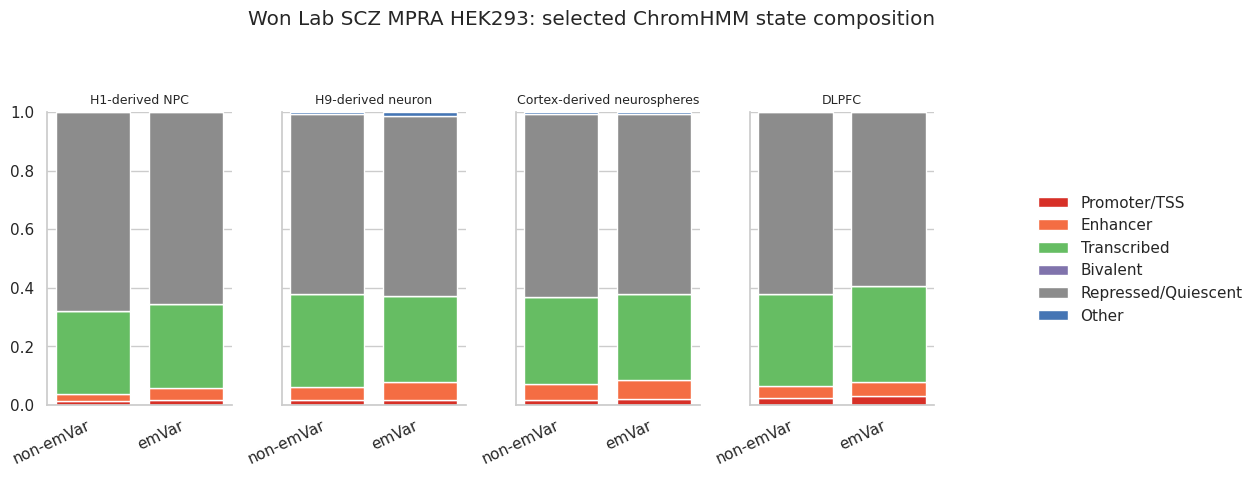

/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
/nas/longleaf/home/mhg/tmp/ipykernel_2583401/2268462168.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['non

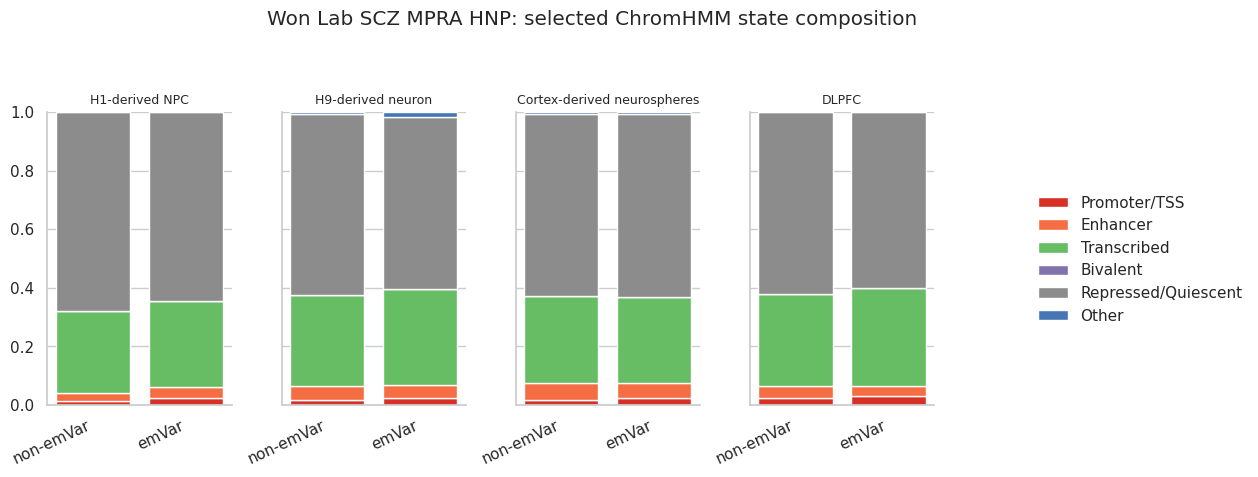

In [9]:
STATE_ORDER = ['Promoter/TSS', 'Enhancer', 'Transcribed', 'Bivalent', 'Repressed/Quiescent', 'Other']
STATE_COLORS = {
    'Promoter/TSS': '#D73027',
    'Enhancer': '#F46D43',
    'Transcribed': '#66BD63',
    'Bivalent': '#8073AC',
    'Repressed/Quiescent': '#8C8C8C',
    'Other': '#4575B4',
}

def plot_chromhmm_dataset(name):
    obj = loaded[name]
    state_df = all_states[all_states['dataset'].eq(name)].copy()
    samples = [c.replace('_15_coreMarks_dense', '') for c in obj['chromhmm_cols']]
    if state_df.empty or not samples:
        return None
    fig, axes = plt.subplots(1, len(samples), figsize=(max(9.2, 3.0 * len(samples)), 4.8), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, sample_id in zip(axes, samples):
        sub = state_df[state_df['sample_id'].eq(sample_id)]
        bottoms = {'non-emVar': 0.0, 'emVar': 0.0}
        for state in STATE_ORDER:
            vals = []
            for cls in ['non-emVar', 'emVar']:
                v = sub.loc[(sub['emVar'].eq(cls)) & (sub['state_group'].eq(state)), 'prop']
                vals.append(float(v.iloc[0]) if len(v) else 0.0)
            ax.bar(['non-emVar', 'emVar'], vals, bottom=[bottoms['non-emVar'], bottoms['emVar']], color=STATE_COLORS[state], label=state)
            bottoms['non-emVar'] += vals[0]
            bottoms['emVar'] += vals[1]
        ax.set_ylim(0, 1)
        ax.set_title(CHROMHMM_LABELS.get(sample_id, sample_id), fontsize=9)
        ax.set_xticklabels(['non-emVar', 'emVar'], rotation=25, ha='right')
        ax.spines[['top', 'right']].set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.86, 0.5), frameon=False)
    fig.suptitle(f"{obj['config']['label']}: selected ChromHMM state composition", y=1.02)
    fig.tight_layout(rect=[0, 0.03, 0.80, 0.96])
    fig.savefig(PLOTDIR / f'{name}_selected_chromhmm_state_proportions.png', dpi=300, bbox_inches='tight')
    return fig

for name in loaded:
    fig = plot_chromhmm_dataset(name)
    if fig is not None:
        plt.show()

## Notes

- This notebook intentionally displays compact per-dataset panels instead of a dense all-dataset heatmap.
- Won Lab is split into ADD MPRA, CDMPRA, CSMPRA, SCZ HEK293, and SCZ HNP readouts from `Integrated_emVar_results_Won_v2.tsv`.
- Won Lab assay-specific panels only include rows with an observed call for that assay column; missing values from other Won Lab assays are not counted as non-emVars.
- Won Lab annotation panels are restricted to brain/neuro-relevant chr_acc signals and brain/neuro ChromHMM epigenomes.
- Neuro cCRE uses the chromatin annotation file as background, matching the previous visualization script.
- Tewhey SK-N-SH, K562, and Won Lab panels are restricted to variants with both emVar calls and chromatin annotations.